In [1]:
import numpy as np
import scipy.io
import glob
import os
import matplotlib.pyplot as plt

from scipy.stats import kurtosis, skew
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM


In [2]:
def extract_features(signal, fs=12000, window_size=1024, overlap=0.5):
    """
    Extracts Time + Frequency features using overlapping windows
    for anomaly detection.
    """
    step = int(window_size * (1 - overlap))
    features = []

    for i in range(0, len(signal) - window_size, step):
        window = signal[i : i + window_size]

        # ---- Time Domain ----
        mean_val = np.mean(window)
        std_val = np.std(window)
        rms_val = np.sqrt(np.mean(window**2))
        peak_val = np.max(np.abs(window))
        kurt_val = kurtosis(window)
        skew_val = skew(window)
        crest_factor = peak_val / (rms_val + 1e-6)

        # ---- Frequency Domain ----
        fft_vals = np.abs(np.fft.rfft(window))
        fft_freqs = np.fft.rfftfreq(window_size, 1/fs)

        peak_freq = fft_freqs[np.argmax(fft_vals)]
        spec_centroid = np.sum(fft_freqs * fft_vals) / (np.sum(fft_vals) + 1e-6)

        # ---- Band Energy ----
        band_low = np.sum(fft_vals[fft_freqs < 1000]**2)
        band_mid = np.sum(fft_vals[(fft_freqs >= 1000) & (fft_freqs < 3000)]**2)
        band_high = np.sum(fft_vals[fft_freqs >= 3000]**2)

        features.append([
            mean_val, std_val, rms_val,
            kurt_val, skew_val, crest_factor,
            peak_freq, spec_centroid,
            band_low, band_mid, band_high
        ])

    return np.array(features)


In [3]:
def load_fault_detection_data(dataset_path):
    normal_train = []
    normal_test = []
    anomaly_test = []

    files = glob.glob(os.path.join(dataset_path, "**", "*.mat"), recursive=True)
    print(f"Processing {len(files)} files...")

    for filepath in files:
        try:
            mat = scipy.io.loadmat(filepath)
            key = next((k for k in mat.keys() if "DE_time" in k), None)
            if key is None:
                continue

            signal = mat[key].flatten()

            if "Normal" in filepath:
                split = int(0.8 * len(signal))
                train_sig = signal[:split]
                test_sig = signal[split:]

                normal_train.append(extract_features(train_sig))
                normal_test.append(extract_features(test_sig))

            else:
                anomaly_test.append(extract_features(signal))

        except:
            pass

    return (
        np.vstack(normal_train),
        np.vstack(normal_test),
        np.vstack(anomaly_test)
    )


In [4]:
dataset_path = r"./CWRU-dataset"

X_train, X_test_normal, X_test_anomaly = load_fault_detection_data(dataset_path)

print("Training (Normal):", X_train.shape)
print("Test Normal:", X_test_normal.shape)
print("Test Anomaly:", X_test_anomaly.shape)


Processing 161 files...
Training (Normal): (2647, 11)
Test Normal: (658, 11)
Test Anomaly: (66751, 11)


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_normal_scaled = scaler.transform(X_test_normal)
X_test_anomaly_scaled = scaler.transform(X_test_anomaly)


In [6]:
model = OneClassSVM(
    kernel="rbf",
    nu=0.01,        # Expect ~1% outliers
    gamma="scale"
)

model.fit(X_train_scaled)

print("One-Class SVM trained on normal data.")


One-Class SVM trained on normal data.


In [7]:
y_pred_normal = model.predict(X_test_normal_scaled)
y_pred_anomaly = model.predict(X_test_anomaly_scaled)

# 1 = Normal, -1 = Anomaly
tn = np.sum(y_pred_normal == 1)
fp = np.sum(y_pred_normal == -1)

tp = np.sum(y_pred_anomaly == -1)
fn = np.sum(y_pred_anomaly == 1)

print("=== Fault Detection Performance ===")
print(f"Fault Detection Rate (Recall): {tp / (tp + fn):.2%}")
print(f"False Alarm Rate: {fp / (fp + tn):.2%}")


=== Fault Detection Performance ===
Fault Detection Rate (Recall): 100.00%
False Alarm Rate: 9.12%


In [8]:
print("\nConfusion Matrix:")
print(f"[[{tp}  Fault Detected, {fn}  Fault Missed]")
print(f" [{fp}  False Alarm,  {tn}  Normal Correct]]")



Confusion Matrix:
[[66751  Fault Detected, 0  Fault Missed]
 [60  False Alarm,  598  Normal Correct]]


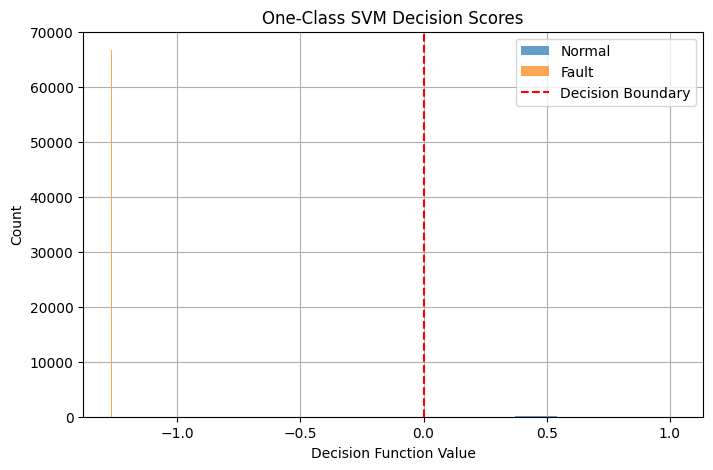

In [13]:
normal_scores = model.decision_function(X_test_normal_scaled)
fault_scores = model.decision_function(X_test_anomaly_scaled)

plt.figure(figsize=(8,5))
plt.hist(normal_scores, bins=50, alpha=0.7, label="Normal")
plt.hist(fault_scores, bins=50, alpha=0.7, label="Fault")
plt.axvline(0, color="red", linestyle="--", label="Decision Boundary")
plt.title("One-Class SVM Decision Scores")
plt.xlabel("Decision Function Value")
plt.ylabel("Count")
plt.legend()
plt.grid(True)
plt.show()


In [14]:
print("Normal scores:")
print("  Min:", normal_scores.min())
print("  Max:", normal_scores.max())

print("\nFault scores:")
print("  Min:", fault_scores.min())
print("  Max:", fault_scores.max())


Normal scores:
  Min: -1.147569101620913
  Max: 1.02046919030027

Fault scores:
  Min: -1.2669135478880924
  Max: -1.1904757575538802


In [15]:
import joblib
# Save the Anomaly Detector and its Scaler
joblib.dump(model, 'anomaly_model.pkl')
joblib.dump(scaler, 'anomaly_scaler.pkl')
print("Anomaly models saved!")

Anomaly models saved!
